<h1>Project Group 30: Predicting Repeat Purchases with ML</h1>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Notebook 2 of 3</b>: Section III. It starts from the prepared data of Notebook 1 and uses the same 4 time folds for every decision and the holdout once at the end.</p>

</div>

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from scipy.stats import chi2_contingency, spearmanr
from scipy.stats.contingency import association

import sklearn
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, GroupKFold, RandomizedSearchCV, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, RobustScaler
from sklearn.tree import DecisionTreeClassifier
from tqdm.auto import tqdm

import preprocessing as prep
from preprocessing import TARGET, RANDOM_STATE, PLOT_BLUE, PLOT_PURPLE

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 90)

# the L1 selection uses l1_ratio=1, older versions silently fit an L2 penalty instead
sklearn_version = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
assert sklearn_version >= (1, 8), f"scikit-learn {sklearn.__version__} found, 1.8 or newer is needed"

In [2]:
# prepared training purchases of notebook 1 and the same split
train = prep.load_interim("../data/interim")
development, holdout, inner_folds = prep.split_development_holdout(train)

X_dev, y_dev = development.drop(columns=TARGET), development[TARGET]
X_holdout, y_holdout = holdout.drop(columns=TARGET), holdout[TARGET]
print(f"Development: {len(X_dev)} rows, repeat rate {y_dev.mean():.3f}")
print(f"Holdout: {len(X_holdout)} rows, repeat rate {y_holdout.mean():.3f}")
print("Inner folds (training rows, validation rows):",
      [(len(fit), len(val)) for fit, val in inner_folds])

Development: 5207 rows, repeat rate 0.549
Holdout: 1078 rows, repeat rate 0.604
Inner folds (training rows, validation rows): [(932, 1041), (1885, 1041), (2992, 1041), (3903, 1041)]


<a id="classification"></a>

<h1>III. Binary Classification & Optimization</h1>

<h2>Explanation of model assessment strategy and metrics used</h2>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>The split is described in Section I (Notebook 1). The folds differ in size (932 to 3,903 training rows) and in repeat rate, so candidates are always compared on the same folds.</p>

</div>

<h3>Metrics and baseline</h3>

In [3]:
# baseline: always predict a repeat
always_repeat = DummyClassifier(strategy="constant", constant=1)
baseline_folds = []
for fold, (fit_idx, val_idx) in enumerate(inner_folds, start=1):
    always_repeat.fit(X_dev.iloc[fit_idx], y_dev.iloc[fit_idx])
    fold_f1 = f1_score(y_dev.iloc[val_idx], always_repeat.predict(X_dev.iloc[val_idx]))
    baseline_folds.append(fold_f1)
    print(f"Inner fold {fold}: repeat rate {y_dev.iloc[val_idx].mean():.3f}, "
          f"F1 of always predicting a repeat {fold_f1:.3f}")
baseline_folds = np.array(baseline_folds)
baseline_holdout = f1_score(y_holdout, np.ones(len(y_holdout)))
print(f"Holdout: repeat rate {y_holdout.mean():.3f}, "
      f"F1 of always predicting a repeat {baseline_holdout:.3f}")
print(f"Mean baseline F1 on the inner folds: {baseline_folds.mean():.4f}")

Inner fold 1: repeat rate 0.591, F1 of always predicting a repeat 0.743
Inner fold 2: repeat rate 0.530, F1 of always predicting a repeat 0.693
Inner fold 3: repeat rate 0.581, F1 of always predicting a repeat 0.735
Inner fold 4: repeat rate 0.510, F1 of always predicting a repeat 0.676
Holdout: repeat rate 0.604, F1 of always predicting a repeat 0.753
Mean baseline F1 on the inner folds: 0.7116


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>F1 of the repeat class</b> decides everything: it is the Kaggle metric, and it balances precision (predicted repeat buyers who return) and recall (repeat buyers found). Accuracy is not used: with 56% repeats it rewards the majority class</li>
  <li><b>AUC</b> is reported next to it, because it measures the ranking independent of a threshold</li>
  <li><b>Baseline</b>: always predicting a repeat gives 0.676 to 0.743 on the folds (mean 0.712) and 0.753 on the holdout --> an F1 is only comparable with candidates on the same period</li>
</ul>

</div>

<h3>How two candidates are compared</h3>

In [4]:
SCORING = {"f1": "f1", "auc": "roc_auc"}


# validation scores of one setting of a search on the 4 inner folds
def setting_folds(search, index, metric="f1"):
    return np.array([search.cv_results_[f"split{fold}_test_{metric}"][index]
                     for fold in range(len(inner_folds))])


# training and validation scores of one setting of a search
def setting_summary(search, index):
    cv_results = search.cv_results_
    return {"Train F1": cv_results["mean_train_f1"][index], "CV F1": cv_results["mean_test_f1"][index],
            "CV F1 std": cv_results["std_test_f1"][index], "CV AUC": cv_results["mean_test_auc"][index]}


# a candidate is better only if its mean F1 beats the reference by more than the larger fold std
def compare_scores(candidate, reference):
    candidate, reference = np.asarray(candidate), np.asarray(reference)
    difference = candidate.mean() - reference.mean()
    spread = max(candidate.std(), reference.std())
    verdict = "better" if difference > spread else "worse" if difference < -spread else "equal"
    return {"F1 difference": difference, "Larger fold std": spread,
            "Folds higher": int((candidate > reference).sum()), "Verdict": verdict}


# the best setting, or its more regularised neighbour if that one is equal in F1 and not lower in AUC
def regularised_setting(search, parameter, weak_to_strong):
    settings = search.cv_results_["params"]
    best = search.best_index_
    position = weak_to_strong.index(settings[best][parameter])
    neighbour = {**settings[best], parameter: weak_to_strong[min(position + 1, len(weak_to_strong) - 1)]}
    if neighbour == settings[best] or neighbour not in settings:
        return best
    stronger = settings.index(neighbour)
    same_f1 = compare_scores(setting_folds(search, stronger), setting_folds(search, best))["Verdict"] == "equal"
    if same_f1 and search.cv_results_["mean_test_auc"][stronger] >= search.cv_results_["mean_test_auc"][best]:
        return stronger
    return best


def grid_search(pipeline, grid):
    search = GridSearchCV(pipeline, grid, cv=inner_folds, scoring=SCORING, refit="f1",
                          return_train_score=True, n_jobs=-1)
    return search.fit(X_dev, y_dev)

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>grid_search</b> runs the search on the time folds and keeps the training scores, so that over- and underfitting stay visible</li>
  <li><b>compare_scores</b>: a candidate is better only if its mean F1 beats the reference by more than the larger of the two fold standard deviations; otherwise both are equal and the simpler option wins</li>
  <li><b>regularised_setting</b>: for a hyperparameter, the best mean F1 is taken, unless the next more regularised value is equal in F1 and not lower in AUC</li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Why this rule</b></p>
<ul>
  <li>The four validation periods differ in their repeat rate (0.510 to 0.591), so the F1 of the same prediction changes from fold to fold: always predicting a repeat scores 0.676 to 0.743</li>
  <li>A difference smaller than this spread can come from which period happens to suit a candidate, so it is no evidence that the candidate is better</li>
  <li>A candidate therefore counts as better only if its mean F1 exceeds the reference by more than the larger of the two fold standard deviations. Otherwise both count as equal and the simpler option stays, because it has fewer choices that could fit noise</li>
  <li>The rule is strict and can miss a small real gain, so the number of folds in which the candidate scores higher is reported next to every comparison</li>
  <li>For a single hyperparameter the rule would always pick the edge of the grid, because a whole flat curve fits inside one standard deviation. There, the best mean F1 decides, and the more regularised neighbour is only taken if its F1 is equal and its AUC, which does not depend on a threshold and varies less, is not lower</li>
</ul>

</div>

<h3>Time folds against customer folds</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>Rows of one customer are not independent, so folds by customer (GroupKFold) would also be a defensible split. Within the training rows of each time fold, a setting is chosen once with customer folds and once with time folds, and both choices are scored on the next period. Fold 1 is left out: its 932 training rows would leave inner time folds of 77 rows.</p>

</div>

In [5]:
candidate_numeric = prep.SUPPLIED_NUMERIC + prep.ROW_FEATURES + prep.CUSTOMER_HISTORY
candidate_flags = prep.STRUCTURAL_FLAGS + prep.ROW_FLAGS
candidate_categorical = prep.PURCHASE_CATEGORIES
C_GRID = {"model__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 10]}
TREE_GRID = {"model__max_depth": [2, 4, 6, 8, 12, None], "model__min_samples_leaf": [1, 25, 50, 100]}
logistic = LogisticRegression(max_iter=5000)
tree = DecisionTreeClassifier(random_state=RANDOM_STATE)


# choose the best setting with one kind of fold, using the training rows of a time fold only
def choose_inside_training(model, grid, fit_idx, split):
    X_fit, y_fit = X_dev.iloc[fit_idx], y_dev.iloc[fit_idx]
    if split == "Customer folds":
        folds = list(GroupKFold(n_splits=4).split(X_fit, y_fit, groups=X_fit["customer_id"]))
    else:
        folds = prep.time_folds(X_fit["purchase_date"], 3)
    pipeline = prep.build_pipeline(model, candidate_numeric, candidate_flags, candidate_categorical)
    return GridSearchCV(pipeline, grid, cv=folds, scoring="f1", n_jobs=-1).fit(X_fit, y_fit)


split_rows = []
split_models = [("Logistic regression", logistic, C_GRID), ("Decision tree", tree, TREE_GRID)]
for model_name, model, grid in tqdm(split_models, desc="models", leave=True, position=0):
    for split in ["Customer folds", "Time folds"]:
        for fold, (fit_idx, val_idx) in enumerate(tqdm(inner_folds[1:], desc=f"{model_name}, {split}",
                                                       unit="fold", leave=False), start=2):
            started = time.perf_counter()
            choice = choose_inside_training(model, grid, fit_idx, split)
            later_f1 = f1_score(y_dev.iloc[val_idx], choice.predict(X_dev.iloc[val_idx]))
            split_rows.append({"Model": model_name, "Split": split, "Fold": fold,
                               "Promised": choice.best_score_, "Reached": later_f1,
                               "Seconds": time.perf_counter() - started})
split_scores = pd.DataFrame(split_rows)
split_scores["Absolute gap"] = (split_scores["Promised"] - split_scores["Reached"]).abs()

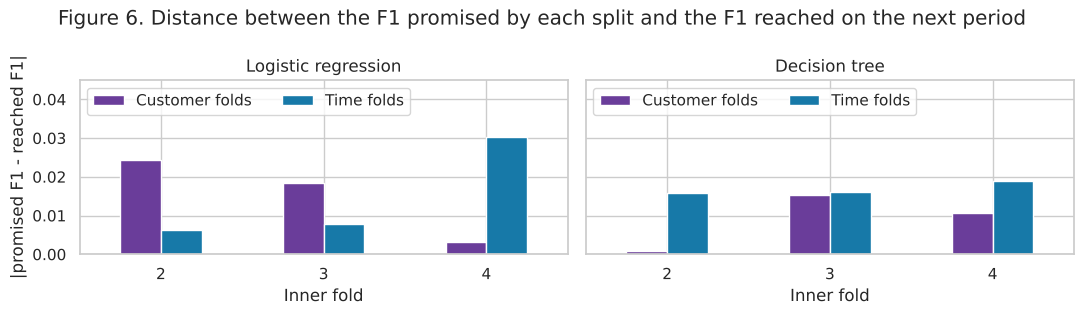

Logistic regression: mean absolute gap customer folds 0.0153, time folds 0.0147; reached F1 customer folds 0.7532, time folds 0.7489, choice by time folds higher in 0 of 3 folds
Decision tree: mean absolute gap customer folds 0.0089, time folds 0.0169; reached F1 customer folds 0.7196, time folds 0.7307, choice by time folds higher in 1 of 3 folds
Seconds for the 3 folds: {('Decision tree', 'Customer folds'): 8.6, ('Decision tree', 'Time folds'): 5.5, ('Logistic regression', 'Customer folds'): 4.5, ('Logistic regression', 'Time folds'): 2.1}


In [6]:
# how far the promised F1 is from the F1 reached on the next period, fold by fold
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, model_name in zip(axes, ["Logistic regression", "Decision tree"]):
    gaps = split_scores[split_scores["Model"] == model_name].pivot(index="Fold", columns="Split",
                                                                   values="Absolute gap")
    gaps.plot(kind="bar", color=[PLOT_PURPLE, PLOT_BLUE], rot=0, ax=ax)
    ax.set(title=model_name, xlabel="Inner fold", ylabel="|promised F1 - reached F1|", ylim=(0, 0.045))
    ax.legend(title="", ncol=2, loc="upper left")
fig.suptitle("Figure 6. Distance between the F1 promised by each split and the F1 reached on the next period")
plt.tight_layout()
plt.show()
for model_name in ["Logistic regression", "Decision tree"]:
    model_scores = split_scores[split_scores["Model"] == model_name]
    means = model_scores.groupby("Split")[["Absolute gap", "Reached"]].mean()
    reached = model_scores.pivot(index="Fold", columns="Split", values="Reached")
    print(f"{model_name}: mean absolute gap customer folds {means.loc['Customer folds', 'Absolute gap']:.4f}, "
          f"time folds {means.loc['Time folds', 'Absolute gap']:.4f}; reached F1 customer folds "
          f"{means.loc['Customer folds', 'Reached']:.4f}, time folds {means.loc['Time folds', 'Reached']:.4f}, "
          f"choice by time folds higher in {(reached['Time folds'] > reached['Customer folds']).sum()} of 3 folds")
print("Seconds for the 3 folds:", split_scores.groupby(["Model", "Split"])["Seconds"].sum().round(1).to_dict())

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight and decision</b></p>
<ul>
  <li><b>Estimate</b>: neither split predicts the later F1 better. The mean distance between promised and reached F1 is 0.0153 (customer folds) and 0.0147 (time folds) for the logistic regression, and 0.0089 and 0.0169 for the decision tree (Figure 6); most of it comes from the repeat rate of the next period</li>
  <li><b>Choice</b>: neither split chooses clearly better settings: reached F1 0.753 against 0.749 for the logistic regression and 0.720 against 0.731 for the decision tree, differences below the fold spread</li>
  <li><b>Decision: time folds</b>, because they test the real use: in the later periods 63% to 88% of the rows come from customers already seen in training (Section I), which customer folds never test, and customer folds train on later periods, so a decision taken on them would use the future</li>
</ul>

</div>

<h3>Leakage checks</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>Two checks before any model is tuned: no single candidate may separate the classes almost perfectly, and a model trained on shuffled labels must fall to chance level.</p>

</div>

In [7]:
# no single candidate may be suspiciously strong on its own
single_auc = {}
for variable in candidate_numeric + candidate_flags:
    auc = roc_auc_score(y_dev, X_dev[variable].fillna(X_dev[variable].median()))
    single_auc[variable] = max(auc, 1 - auc)
single_auc = pd.Series(single_auc).sort_values(ascending=False)
print(f"Strongest single variable: {single_auc.index[0]} (AUC {single_auc.iloc[0]:.3f}), "
      f"variables above 0.9: {(single_auc > 0.9).sum()}")

# the same model trained on shuffled labels must fall to chance level
check_pipeline = prep.build_pipeline(LogisticRegression(C=0.01, max_iter=5000), candidate_numeric,
                                     candidate_flags, candidate_categorical)
real_scores = cross_validate(check_pipeline, X_dev, y_dev, cv=inner_folds, scoring=SCORING)
for seed in tqdm(range(3), desc="shuffled labels", leave=True, position=0):
    shuffled = pd.Series(np.random.RandomState(seed).permutation(y_dev.to_numpy()), index=y_dev.index)
    shuffled_scores = cross_validate(check_pipeline, X_dev, shuffled, cv=inner_folds, scoring=SCORING)
    print(f"Shuffled labels, seed {seed}: F1 {shuffled_scores['test_f1'].mean():.4f}, "
          f"AUC {shuffled_scores['test_auc'].mean():.4f}")
print(f"Real labels: F1 {real_scores['test_f1'].mean():.4f}, AUC {real_scores['test_auc'].mean():.4f}")

Strongest single variable: purchase_count_365d (AUC 0.746), variables above 0.9: 0
Shuffled labels, seed 0: F1 0.6524, AUC 0.4940
Shuffled labels, seed 1: F1 0.6805, AUC 0.5028
Shuffled labels, seed 2: F1 0.6666, AUC 0.5065
Real labels: F1 0.7571, AUC 0.7976


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li>The strongest single variable, <b>purchase_count_365d</b>, reaches an AUC of 0.746, and none exceeds 0.9 --> no variable carries the target itself</li>
  <li>With shuffled labels the AUC falls to 0.494 to 0.507 and the F1 to 0.652 to 0.681, below the baseline of 0.712; with the real labels: F1 0.757, AUC 0.798 --> the scores come from real patterns, not from leakage</li>
</ul>

</div>

<h3>Additional pre-processing</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>Notebook 1 chose the pre-processing based on the exploration. Here every choice is tested against alternatives: each variant changes one choice of the reference (logistic regression on all candidates, with C tuned per variant).</p>

</div>

In [8]:
# undo the 0 of the structural fill, so that the pipeline fills these values itself
def structural_gaps_to_missing(purchases):
    purchases = purchases.copy()
    for col, needed in prep.PURCHASES_NEEDED.items():
        purchases.loc[purchases["prior_purchase_count"] < needed, col] = np.nan
    return purchases


# flag for a missing warehouse, the one random gap that is linked to the target (Notebook 1)
def add_warehouse_flag(purchases):
    return purchases.assign(warehouse_missing=purchases["warehouse"].isna().astype(int))


def candidate_pipeline(flags=candidate_flags, **prep_options):
    return prep.build_pipeline(logistic, candidate_numeric, flags, candidate_categorical, **prep_options)


# every variant changes one choice of the reference
variants = {
    "Reference": (candidate_pipeline(), X_dev),
    "Without log1p": (candidate_pipeline(use_log=False), X_dev),
    "MinMaxScaler instead of StandardScaler": (candidate_pipeline(scaler=MinMaxScaler), X_dev),
    "RobustScaler instead of StandardScaler": (candidate_pipeline(scaler=RobustScaler), X_dev),
    "Mean instead of median": (candidate_pipeline(impute="mean"), X_dev),
    "Rare levels: fewer than 10 rows": (candidate_pipeline(min_frequency=10), X_dev),
    "Rare levels: fewer than 100 rows": (candidate_pipeline(min_frequency=100), X_dev),
    "Structural gaps: median instead of 0": (candidate_pipeline(), structural_gaps_to_missing(X_dev)),
    "Without the two structural flags": (candidate_pipeline(flags=prep.ROW_FLAGS), X_dev),
    "With a flag for a missing warehouse": (candidate_pipeline(flags=candidate_flags + ["warehouse_missing"]),
                                            add_warehouse_flag(X_dev)),
}
variant_searches = {}
variants_started = time.perf_counter()
for name, (pipeline, X_variant) in tqdm(variants.items(), desc="pre-processing variants", leave=True, position=0):
    variant_searches[name] = GridSearchCV(pipeline, C_GRID, cv=inner_folds, scoring=SCORING, refit="f1",
                                          return_train_score=True, n_jobs=-1).fit(X_variant, y_dev)
reference_search = variant_searches["Reference"]
reference_C = reference_search.best_params_["model__C"]
reference_folds = setting_folds(reference_search, reference_search.best_index_)

# capping at quantiles of the training part of each fold, with the C of the reference
capped_columns = [col for col in candidate_numeric if col not in prep.PLAIN_COLUMNS]
capped_folds = {}
for lower, upper in [(0.01, 0.99), (0.05, 0.95)]:
    fold_f1 = []
    for fit_idx, val_idx in tqdm(inner_folds, desc=f"capping {lower:.0%} / {upper:.0%}", unit="fold", leave=False):
        fit_part, val_part = prep.winsorize(X_dev.iloc[fit_idx], X_dev.iloc[val_idx], capped_columns, lower, upper)
        fitted = candidate_pipeline().set_params(model__C=reference_C).fit(fit_part, y_dev.iloc[fit_idx])
        fold_f1.append(f1_score(y_dev.iloc[val_idx], fitted.predict(val_part)))
    capped_folds[f"Capping at {lower:.0%} / {upper:.0%} before log1p"] = np.array(fold_f1)
print(f"{len(variants) + len(capped_folds)} variants on 4 folds: {time.perf_counter() - variants_started:.0f} seconds")

12 variants on 4 folds: 20 seconds


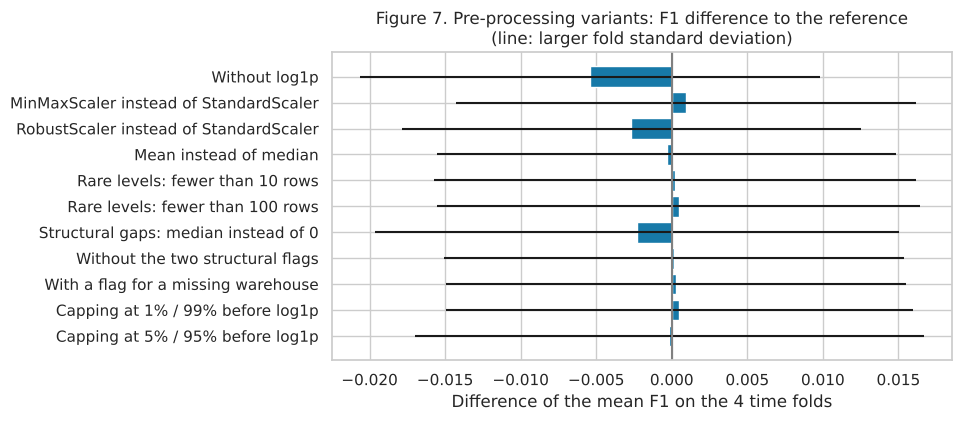

Reference: CV F1 0.7571 ± 0.0152, best C 0.01
Without log1p: -0.0054 (larger fold std 0.0152, higher in 1 of 4 folds, equal)
MinMaxScaler instead of StandardScaler: +0.0010 (larger fold std 0.0152, higher in 2 of 4 folds, equal)
RobustScaler instead of StandardScaler: -0.0027 (larger fold std 0.0152, higher in 2 of 4 folds, equal)
Mean instead of median: -0.0003 (larger fold std 0.0152, higher in 1 of 4 folds, equal)
Rare levels: fewer than 10 rows: +0.0002 (larger fold std 0.0160, higher in 1 of 4 folds, equal)
Rare levels: fewer than 100 rows: +0.0005 (larger fold std 0.0160, higher in 2 of 4 folds, equal)
Structural gaps: median instead of 0: -0.0023 (larger fold std 0.0173, higher in 2 of 4 folds, equal)
Without the two structural flags: +0.0002 (larger fold std 0.0152, higher in 1 of 4 folds, equal)
With a flag for a missing warehouse: +0.0003 (larger fold std 0.0152, higher in 1 of 4 folds, equal)
Capping at 1% / 99% before log1p: +0.0005 (larger fold std 0.0155, higher in 2 of 4

In [9]:
# every pre-processing variant against the reference on the same folds
variant_folds = {name: setting_folds(search, search.best_index_)
                 for name, search in variant_searches.items() if name != "Reference"}
variant_folds.update(capped_folds)
variant_results = pd.DataFrame({name: compare_scores(folds, reference_folds)
                                for name, folds in variant_folds.items()}).T

fig, ax = plt.subplots(figsize=(8, 4))
shown_variants = variant_results.iloc[::-1]
ax.barh(shown_variants.index, shown_variants["F1 difference"].astype(float),
        xerr=shown_variants["Larger fold std"].astype(float), color=PLOT_BLUE)
ax.axvline(0, color="grey")
ax.set(title="Figure 7. Pre-processing variants: F1 difference to the reference\n(line: larger fold standard deviation)",
       xlabel="Difference of the mean F1 on the 4 time folds")
plt.show()
print(f"Reference: CV F1 {reference_folds.mean():.4f} ± {reference_folds.std():.4f}, best C {reference_C}")
for name, variant in variant_results.iterrows():
    print(f"{name}: {variant['F1 difference']:+.4f} (larger fold std {variant['Larger fold std']:.4f}, "
          f"higher in {variant['Folds higher']} of 4 folds, {variant['Verdict']})")

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight and decision</b></p>
<ul>
  <li>No variant is better or worse than the reference (Figure 7), so the choices of Notebook 1 stay, and in a tie the simpler or more plausible option is kept</li>
  <li><b>log1p</b>: without it the F1 is 0.0054 lower, the largest loss, and higher in only 1 of 4 folds --> kept: it makes the skewed amounts roughly symmetric, so the linear model treats a step in activity alike for small and big customers</li>
  <li><b>Capping</b> at the 1% / 99% (+0.0005) or 5% / 95% (-0.0002) training quantiles --> not used: after log1p the large amounts no longer dominate, and the big customers are informative (Notebook 1)</li>
  <li><b>Scaler</b>: MinMaxScaler (+0.0010) and RobustScaler (-0.0027) --> StandardScaler stays: after log1p the columns are roughly symmetric, and the L2 penalty then treats all columns alike</li>
  <li><b>Imputation</b> (mean -0.0003) and <b>rare-level limit</b> (10 rows +0.0002, 100 rows +0.0005) --> median and 30 rows stay: only about 3% of the values are missing and few levels are rare, so these choices touch few rows</li>
  <li><b>Structural gaps</b>: median instead of 0 (-0.0023), without the two flags (+0.0002), warehouse flag (+0.0003) --> the 0 stays, because a median would pretend that a first purchase has a typical history; the flags go to the feature selection</li>
</ul>

</div>

<h2>Feature Selection Strategy and results</h2>

<h3>Strategy</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>Candidates</b>: the 38 variables of Notebook 1 plus random_noise as a benchmark. Identifier-like variables and clientes.csv were excluded with evidence in Notebook 1</li>
  <li><b>One method per family</b>, on the development part: a filter (statistics, no model), a wrapper (RFE) and an embedded method (L1 penalty)</li>
  <li><b>Variables, not columns</b>: a categorical variable is kept if at least one of its one-hot columns is kept</li>
  <li><b>Decision rule, fixed in advance</b>: a variable enters the final set with at least 2 of 3 votes. The final set replaces the candidate list if its F1 is not worse</li>
  <li><b>Honest estimate</b>: the whole selection is repeated inside every fold at the end, so that its score is not measured on rows it has seen</li>
</ul>

</div>

<h3>Method 1: filter</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>A variable passes if its link with the target is significant (p < 0.05; Spearman for numbers and flags, chi-square for categories) and if it is not a near-copy of a stronger kept variable (Spearman of 0.85 or more). Three limits for a near-copy are compared below.</p>

</div>

In [10]:
# filter: significance and redundancy, computed on the rows that are passed in
selection_numeric = candidate_numeric + ["random_noise"]
selection_candidates = selection_numeric + candidate_flags + candidate_categorical


def filter_variables(X_part, y_part, limit=0.85):
    relevance = {}
    for variable in selection_numeric + candidate_flags:
        rho, p_value = spearmanr(X_part[variable], y_part, nan_policy="omit")
        relevance[variable] = {"Measure": "Spearman", "Strength": abs(rho), "p-value": p_value}
    for variable in candidate_categorical:
        crosstab = pd.crosstab(X_part[variable].fillna("missing"), y_part)
        relevance[variable] = {"Measure": "Cramér's V", "Strength": association(crosstab, method="cramer"),
                               "p-value": chi2_contingency(crosstab).pvalue}
    relevance = pd.DataFrame(relevance).T.infer_objects().sort_values("Strength", ascending=False)
    correlation = X_part[selection_numeric].corr(method="spearman").abs()
    kept, redundant_with = [], {}
    for variable in relevance.index[relevance["p-value"] < 0.05]:
        twins = [other for other in kept if variable in correlation.index and other in correlation.index
                 and correlation.loc[variable, other] >= limit]
        if twins:
            redundant_with[variable] = twins[0]
        else:
            kept.append(variable)
    return kept, relevance, redundant_with


# split a list of variables into numeric, flag and categorical variables
def variable_lists(variables):
    return ([variable for variable in variables if variable in selection_numeric],
            [variable for variable in variables if variable in candidate_flags],
            [variable for variable in variables if variable in candidate_categorical])


# three limits for a near-copy: number of variables kept and validation F1 of the kept set
for limit in tqdm([0.75, 0.85, 0.95], desc="redundancy limits", leave=True, position=0):
    kept_at_limit = filter_variables(X_dev, y_dev, limit)[0]
    limit_search = grid_search(prep.build_pipeline(logistic, *variable_lists(kept_at_limit)), C_GRID)
    limit_summary = setting_summary(limit_search, limit_search.best_index_)
    print(f"Limit {limit}: {len(kept_at_limit)} variables kept, CV F1 {limit_summary['CV F1']:.4f} "
          f"± {limit_summary['CV F1 std']:.4f}")

kept_by_filter, relevance, redundant_with = filter_variables(X_dev, y_dev)
print(f"\nFilter with limit 0.85 keeps {len(kept_by_filter)} of {len(selection_candidates)} variables")
print("Not significant:", ", ".join(relevance.index[relevance["p-value"] >= 0.05]))
print("Redundant:", ", ".join(f"{variable} (with {twin})" for variable, twin in redundant_with.items()))

Limit 0.75: 22 variables kept, CV F1 0.7529 ± 0.0140
Limit 0.85: 24 variables kept, CV F1 0.7523 ± 0.0166
Limit 0.95: 34 variables kept, CV F1 0.7569 ± 0.0132

Filter with limit 0.85 keeps 24 of 39 variables
Not significant: Custo, prior_std_gap_days, Total Portes, random_noise
Redundant: prior_repeat_share (with purchases_per_year), recent_repeat_share (with purchases_per_year), purchase_count_180d (with purchase_count_365d), spend_180d (with spend_365d), spend_90d (with purchase_count_90d), prior_total_spend (with spend_365d), spend_30d (with purchase_count_30d), prior_std_purchase_value (with prior_max_purchase_value), Total Desc_ Linha (with discount_rate), prior_mean_purchase_value (with prior_max_purchase_value), Total Liquido (with Total Imp_)


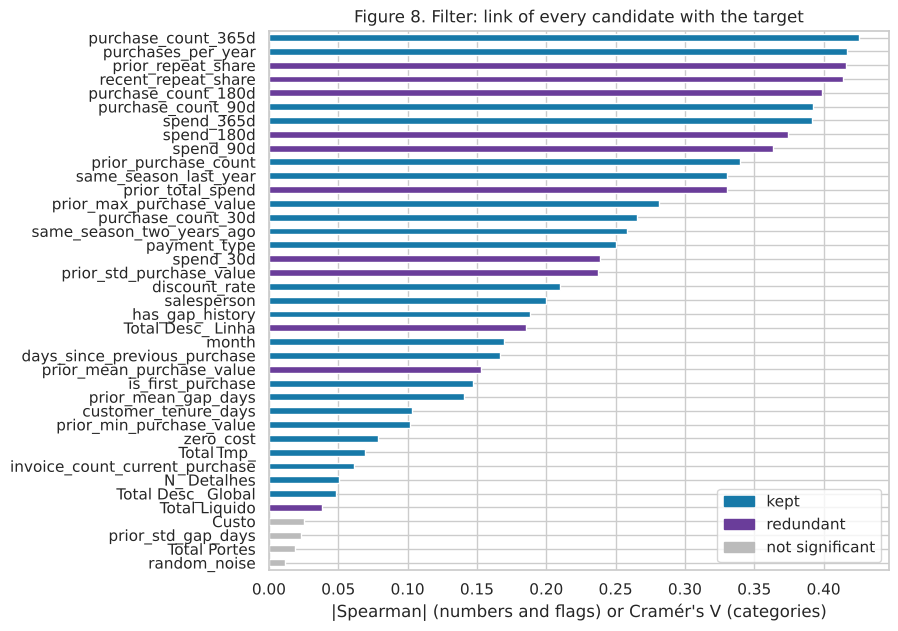

In [11]:
# strength of every variable, coloured by the decision of the filter
status = pd.Series("kept", index=relevance.index)
status[relevance["p-value"] >= 0.05] = "not significant"
status[list(redundant_with)] = "redundant"
status_colors = {"kept": PLOT_BLUE, "redundant": PLOT_PURPLE, "not significant": "#BBBBBB"}

ax = relevance["Strength"][::-1].plot(kind="barh", color=status.map(status_colors)[::-1], figsize=(8, 7))
ax.legend(handles=[Patch(color=color, label=label) for label, color in status_colors.items()],
          loc="lower right")
ax.set(title="Figure 8. Filter: link of every candidate with the target",
       xlabel="|Spearman| (numbers and flags) or Cramér's V (categories)", ylabel="")
plt.show()

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>A limit of 0.75 keeps 22 variables (F1 0.7529 ± 0.0140), 0.85 keeps 24 (0.7523 ± 0.0166) and 0.95 keeps 34 (0.7569 ± 0.0132): all equal under the rule. 0.85 stays: it removes the 11 near-copies (e.g. spend_180d next to spend_365d) without a loss, while 0.95 keeps them and 0.75 also removes variables that are only related.</p>

</div>

<h3>Method 2: wrapper (RFE)</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>RFE with a logistic regression removes the weakest column step by step. It is part of the pipeline, so the columns are selected again in every fold, and the number of columns is tuned from 10 to 50.</p>

</div>

In [12]:
# wrapper: RFE inside the pipeline, the number of columns is tuned on the time folds
selection_preprocessor = prep.build_preprocessor(selection_numeric, candidate_flags, candidate_categorical)
n_columns = selection_preprocessor.fit(X_dev).get_feature_names_out().size


def rfe_pipeline(n_select=None):
    return Pipeline([
        ("prep", clone(selection_preprocessor)),
        ("select", RFE(LogisticRegression(C=reference_C, max_iter=5000), n_features_to_select=n_select)),
        ("model", LogisticRegression(C=reference_C, max_iter=5000)),
    ])


# variables behind the columns that a fitted selector keeps
def kept_variables(fitted, mask):
    names = fitted["prep"].get_feature_names_out()
    return sorted({prep.source_variable(name, candidate_categorical) for name in names[mask]})


rfe_search = grid_search(rfe_pipeline(), {"select__n_features_to_select": [10, 15, 20, 25, 30, 40, 50]})
best_n_columns = rfe_search.best_params_["select__n_features_to_select"]
kept_by_rfe = kept_variables(rfe_search.best_estimator_, rfe_search.best_estimator_["select"].support_)
print(f"Best number of columns: {best_n_columns} of {n_columns}, they belong to {len(kept_by_rfe)} variables")

Best number of columns: 25 of 62, they belong to 18 variables


<h3>Method 3: embedded (L1 penalty)</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>A logistic regression with an L1 penalty sets the coefficients of weak columns to exactly 0. Six values of C are tested, and the variables with a non-zero coefficient are kept.</p>

</div>

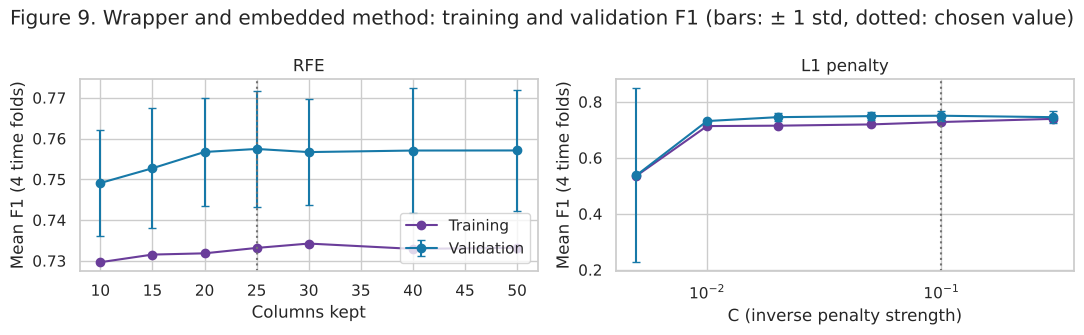

RFE: validation F1 {10: 0.7491, 15: 0.7527, 20: 0.7567, 25: 0.7574, 30: 0.7567, 40: 0.757, 50: 0.7571}
RFE: training F1 {10: 0.7296, 15: 0.7315, 20: 0.7318, 25: 0.7332, 30: 0.7342, 40: 0.7329, 50: 0.7332}
L1 penalty: validation F1 {0.005: 0.5379, 0.01: 0.7312, 0.02: 0.7451, 0.05: 0.7488, 0.1: 0.7502, 0.3: 0.7451}
L1 penalty: training F1 {0.005: 0.5358, 0.01: 0.7133, 0.02: 0.7147, 0.05: 0.7192, 0.1: 0.7278, 0.3: 0.739}
L1 with C = 0.1: 32 of 62 coefficients are not 0 (25 variables)


In [13]:
def l1_pipeline(C=None):
    return Pipeline([
        ("prep", clone(selection_preprocessor)),
        ("model", LogisticRegression(C=C or 1.0, l1_ratio=1, solver="liblinear", max_iter=5000,
                                     random_state=RANDOM_STATE)),
    ])


l1_search = grid_search(l1_pipeline(), {"model__C": [0.005, 0.01, 0.02, 0.05, 0.1, 0.3]})
best_l1_C = l1_search.best_params_["model__C"]
l1_mask = l1_search.best_estimator_["model"].coef_[0] != 0
kept_by_l1 = kept_variables(l1_search.best_estimator_, l1_mask)

# validation curves of the wrapper and the embedded method, the dashed line marks the best value
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
searched = [(rfe_search, "select__n_features_to_select", "RFE", "Columns kept"),
            (l1_search, "model__C", "L1 penalty", "C (inverse penalty strength)")]
for ax, (search, parameter, title, label) in zip(axes, searched):
    curve_data = pd.DataFrame(search.cv_results_).set_index(f"param_{parameter}")
    ax.plot(curve_data.index, curve_data["mean_train_f1"], marker="o", color=PLOT_PURPLE, label="Training")
    ax.errorbar(curve_data.index.astype(float), curve_data["mean_test_f1"], yerr=curve_data["std_test_f1"],
                marker="o", capsize=3, color=PLOT_BLUE, label="Validation")
    ax.axvline(search.best_params_[parameter], color="0.45", linestyle=":", linewidth=1.5)
    ax.set(title=title, xlabel=label, ylabel="Mean F1 (4 time folds)")
axes[1].set_xscale("log")
axes[0].legend(loc="lower right")
fig.suptitle("Figure 9. Wrapper and embedded method: training and validation F1 (bars: ± 1 std, dotted: chosen value)")
plt.tight_layout()
plt.show()
for search, parameter, title, _ in searched:
    curve_data = pd.DataFrame(search.cv_results_).set_index(f"param_{parameter}")
    print(f"{title}: validation F1 {curve_data['mean_test_f1'].round(4).to_dict()}")
    print(f"{title}: training F1 {curve_data['mean_train_f1'].round(4).to_dict()}")
print(f"L1 with C = {best_l1_C}: {l1_mask.sum()} of {n_columns} coefficients are not 0 ({len(kept_by_l1)} variables)")

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Why these values</b></p>
<ul>
  <li><b>RFE</b>: the validation F1 rises from 0.749 with 10 columns to 0.757 with 25 and stays flat up to 50 --> with fewer than about 20 columns the model loses information (underfitting), and further columns add nothing because the L2 penalty already shrinks them. 25 columns have the highest mean. The training F1 (0.730 to 0.734) stays below the validation F1 because the training rows include early years with fewer repeats</li>
  <li><b>L1</b>: at C = 0.005 the penalty sets almost every coefficient to 0 and the F1 falls to 0.538 (underfitting); from C = 0.02 the curve is flat (0.745 to 0.750). C = 0.1 has the highest mean; at C = 0.3 the training F1 rises (0.739) while the validation F1 falls (0.745), the start of overfitting. At C = 0.1, 32 of 62 coefficients stay, among them random_noise</li>
</ul>

</div>

<h3>Results: the vote and the final feature set</h3>

In [14]:
# one vote per method for every variable
votes = pd.DataFrame({
    "Filter": [variable in kept_by_filter for variable in selection_candidates],
    "RFE": [variable in kept_by_rfe for variable in selection_candidates],
    "L1": [variable in kept_by_l1 for variable in selection_candidates],
}, index=selection_candidates)
votes["Votes"] = votes.sum(axis=1)
votes["Final set"] = votes["Votes"] >= 2

final_variables = votes.index[votes["Final set"]].tolist()
FINAL_NUMERIC = [variable for variable in final_variables if variable in candidate_numeric]
FINAL_FLAGS = [variable for variable in final_variables if variable in candidate_flags]
FINAL_CATEGORICAL = [variable for variable in final_variables if variable in candidate_categorical]

for n_votes in [3, 2, 1, 0]:
    with_n_votes = votes.index[votes["Votes"] == n_votes]
    print(f"{n_votes} votes ({len(with_n_votes)}):", ", ".join(with_n_votes))
noise_votes = votes.loc["random_noise", ["Filter", "RFE", "L1"]]
print(f"\nFinal set: {len(final_variables)} of {len(selection_candidates) - 1} candidate variables")
print("random_noise is kept by:", ", ".join(noise_votes.index[noise_votes]) or "no method")

3 votes (12): Total Imp_, customer_tenure_days, prior_mean_gap_days, purchase_count_90d, purchase_count_365d, discount_rate, same_season_last_year, same_season_two_years_ago, zero_cost, payment_type, salesperson, month
2 votes (8): Total Desc_ Global, Total Desc_ Linha, N_ Detalhes, prior_std_purchase_value, prior_max_purchase_value, purchase_count_180d, spend_30d, prior_repeat_share
1 votes (15): Total Portes, Custo, invoice_count_current_purchase, days_since_previous_purchase, prior_purchase_count, prior_std_gap_days, prior_min_purchase_value, purchase_count_30d, spend_90d, spend_365d, purchases_per_year, recent_repeat_share, random_noise, is_first_purchase, has_gap_history
0 votes (4): Total Liquido, prior_total_spend, prior_mean_purchase_value, spend_180d

Final set: 20 of 38 candidate variables
random_noise is kept by: L1


In [15]:
# the single methods and three vote limits, to see what the limit of 2 votes costs
feature_sets = {
    "All candidates": candidate_numeric + candidate_flags + candidate_categorical,
    "Filter": kept_by_filter,
    "RFE": kept_by_rfe,
    "L1": kept_by_l1,
    "1 vote or more": votes.index[votes["Votes"] >= 1].tolist(),
    "2 votes or more (final set)": final_variables,
    "3 votes": votes.index[votes["Votes"] == 3].tolist(),
}
set_searches = {}
for name, variables in tqdm(feature_sets.items(), desc="feature sets", leave=True, position=0):
    set_searches[name] = grid_search(prep.build_pipeline(logistic, *variable_lists(variables)), C_GRID)
set_scores = pd.DataFrame({name: setting_summary(search, search.best_index_)
                           for name, search in set_searches.items()}).T

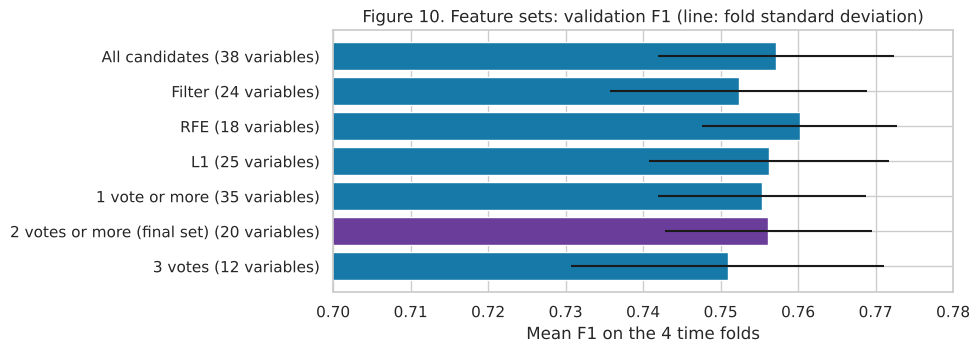

All candidates: 38 variables, CV F1 0.7571 ± 0.0152, CV AUC 0.7976, best C 0.01, against all candidates +0.0000 (equal, higher in 0 of 4)
Filter: 24 variables, CV F1 0.7523 ± 0.0166, CV AUC 0.7944, best C 0.01, against all candidates -0.0048 (equal, higher in 2 of 4)
RFE: 18 variables, CV F1 0.7602 ± 0.0126, CV AUC 0.8001, best C 0.01, against all candidates +0.0031 (equal, higher in 4 of 4)
L1: 25 variables, CV F1 0.7562 ± 0.0155, CV AUC 0.7976, best C 0.01, against all candidates -0.0009 (equal, higher in 2 of 4)
1 vote or more: 35 variables, CV F1 0.7553 ± 0.0134, CV AUC 0.7968, best C 0.01, against all candidates -0.0018 (equal, higher in 1 of 4)
2 votes or more (final set): 20 variables, CV F1 0.7562 ± 0.0134, CV AUC 0.7992, best C 0.01, against all candidates -0.0009 (equal, higher in 2 of 4)
3 votes: 12 variables, CV F1 0.7509 ± 0.0202, CV AUC 0.7945, best C 0.01, against all candidates -0.0062 (equal, higher in 1 of 4)


In [16]:
# validation F1 of the feature sets
labels = [f"{name} ({len(feature_sets[name])} variables)" for name in set_scores.index]
colors = [PLOT_PURPLE if "final" in name else PLOT_BLUE for name in set_scores.index]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(labels[::-1], set_scores["CV F1"][::-1], xerr=set_scores["CV F1 std"][::-1], color=colors[::-1])
ax.set(title="Figure 10. Feature sets: validation F1 (line: fold standard deviation)",
       xlabel="Mean F1 on the 4 time folds", xlim=(0.70, 0.78))
plt.show()

all_candidates_folds = setting_folds(set_searches["All candidates"], set_searches["All candidates"].best_index_)
for name, search in set_searches.items():
    comparison = compare_scores(setting_folds(search, search.best_index_), all_candidates_folds)
    print(f"{name}: {len(feature_sets[name])} variables, CV F1 {set_scores.loc[name, 'CV F1']:.4f} "
          f"± {set_scores.loc[name, 'CV F1 std']:.4f}, CV AUC {set_scores.loc[name, 'CV AUC']:.4f}, "
          f"best C {search.best_params_['model__C']}, against all candidates "
          f"{comparison['F1 difference']:+.4f} ({comparison['Verdict']}, higher in {comparison['Folds higher']} of 4)")

In [17]:
# honest estimate: the whole selection repeated on the training rows of every fold
honest_f1 = []
for fit_idx, val_idx in tqdm(inner_folds, desc="selection inside the folds", unit="fold", leave=True, position=0):
    started = time.perf_counter()
    X_fit, y_fit = X_dev.iloc[fit_idx], y_dev.iloc[fit_idx]
    fold_filter = filter_variables(X_fit, y_fit)[0]
    fold_rfe = rfe_pipeline(best_n_columns).fit(X_fit, y_fit)
    fold_l1 = l1_pipeline(best_l1_C).fit(X_fit, y_fit)
    fold_votes = pd.Series(0, index=selection_candidates)
    for kept in [fold_filter, kept_variables(fold_rfe, fold_rfe["select"].support_),
                 kept_variables(fold_l1, fold_l1["model"].coef_[0] != 0)]:
        fold_votes[kept] += 1
    fold_set = fold_votes.index[fold_votes >= 2].tolist()
    fold_model = prep.build_pipeline(LogisticRegression(C=reference_C, max_iter=5000), *variable_lists(fold_set))
    fold_model.fit(X_fit, y_fit)
    honest_f1.append(f1_score(y_dev.iloc[val_idx], fold_model.predict(X_dev.iloc[val_idx])))
    print(f"Fold: {len(fold_set)} variables selected on the training rows only, "
          f"validation F1 {honest_f1[-1]:.4f}, {time.perf_counter() - started:.1f} seconds")
honest_f1 = np.array(honest_f1)
print(f"Selection inside the folds: F1 {honest_f1.mean():.4f} ± {honest_f1.std():.4f}")

Fold: 16 variables selected on the training rows only, validation F1 0.7800, 0.3 seconds
Fold: 22 variables selected on the training rows only, validation F1 0.7603, 0.4 seconds
Fold: 18 variables selected on the training rows only, validation F1 0.7506, 0.5 seconds
Fold: 21 variables selected on the training rows only, validation F1 0.7357, 0.7 seconds
Selection inside the folds: F1 0.7566 ± 0.0161


In [18]:
# does the final set also work for a model that is not linear?
forest = RandomForestClassifier(n_estimators=200, min_samples_leaf=20, random_state=RANDOM_STATE)
forest_folds = {}
for name in ["All candidates", "2 votes or more (final set)"]:
    forest_pipeline = prep.build_pipeline(forest, *variable_lists(feature_sets[name]))
    forest_scores = cross_validate(forest_pipeline, X_dev, y_dev, cv=inner_folds, scoring=SCORING, n_jobs=-1)
    forest_folds[name] = forest_scores["test_f1"]
forest_result = compare_scores(forest_folds["2 votes or more (final set)"],
                               forest_folds["All candidates"])
print(f"Random forest, CV F1 with all candidates: {forest_folds['All candidates'].mean():.4f}, "
      f"with the final set: {forest_folds['2 votes or more (final set)'].mean():.4f} "
      f"({forest_result['F1 difference']:+.4f}, {forest_result['Verdict']})")

Random forest, CV F1 with all candidates: 0.7511, with the final set: 0.7498 (-0.0013, equal)


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Results</b></p>
<ul>
  <li><b>Filter</b>: keeps 24 variables; random_noise is not significant, 11 are near-copies of a stronger variable</li>
  <li><b>RFE</b> keeps 25 columns (18 variables), <b>L1</b> keeps 25 variables including random_noise --> one method alone is not reliable, hence the vote</li>
  <li><b>Vote limit</b>: 1, 2 and 3 votes keep 35, 20 and 12 variables (F1 0.7553, 0.7562 and 0.7509), all equal to the 38 candidates (0.7571). 3 votes lose the most and spread the most (± 0.0202) because they drop useful variables such as prior_repeat_share; 2 votes is the smallest set without a visible loss (Figure 10)</li>
  <li>RFE alone has the highest mean (0.7602, higher in 4 of 4 folds) but is still equal under the rule; the vote stays because it was fixed in advance and does not rest on one model</li>
  <li><b>Honest estimate</b>: with the whole selection repeated on the training rows of every fold (16 to 22 variables per fold), the F1 is 0.7566 ± 0.0161, the same as 0.7562 for the final set --> selecting on all development rows did not inflate the score</li>
  <li>The final set also works for a random forest (0.7498 against 0.7511 with all candidates, equal)</li>
  <li><b>Decision</b>: the 20 variables with at least 2 votes</li>
</ul>

</div>

<h2>Optimization efforts: presentation, results and discussion</h2>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>Eight algorithms are tuned on the same 4 time folds and the selected variables.</p>
<ul>
  <li><b>Grid search</b> for the models with few hyperparameters: logistic regression (C, class_weight), Gaussian Naive Bayes (var_smoothing), kNN (n_neighbors, weights) and decision tree (max_depth, min_samples_leaf, ccp_alpha, class_weight)</li>
  <li><b>Random search with 60 settings</b> for random forest, gradient boosting and the neural network: a full grid would need thousands of fits, and 60 random settings include one of the best 5% with a probability of 95% (1 - 0.95^60)</li>
  <li><b>Voting</b>: soft vote of four tuned models that work in different ways</li>
</ul>

</div>

<h3>Default settings</h3>

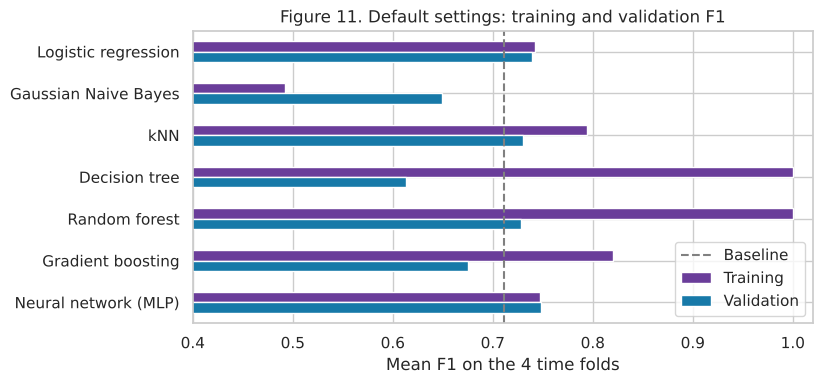

Logistic regression: training 0.742, validation 0.739 ± 0.012, 0.15 seconds for 4 folds
Gaussian Naive Bayes: training 0.492, validation 0.649 ± 0.041, 0.10 seconds for 4 folds
kNN: training 0.795, validation 0.730 ± 0.022, 0.09 seconds for 4 folds
Decision tree: training 1.000, validation 0.613 ± 0.023, 0.17 seconds for 4 folds
Random forest: training 1.000, validation 0.729 ± 0.015, 1.57 seconds for 4 folds
Gradient boosting: training 0.820, validation 0.675 ± 0.040, 2.50 seconds for 4 folds
Neural network (MLP): training 0.747, validation 0.749 ± 0.025, 0.87 seconds for 4 folds


In [19]:
def model_pipeline(model):
    return prep.build_pipeline(model, FINAL_NUMERIC, FINAL_FLAGS, FINAL_CATEGORICAL)


# training and validation scores of one pipeline, fold by fold, with the fit time of every fold
def fold_by_fold(pipeline, name):
    train_f1, validation_f1, validation_auc, seconds = [], [], [], []
    for fit_idx, val_idx in tqdm(inner_folds, desc=name, unit="fold", leave=False):
        started = time.perf_counter()
        fitted = clone(pipeline).fit(X_dev.iloc[fit_idx], y_dev.iloc[fit_idx])
        seconds.append(time.perf_counter() - started)
        train_f1.append(f1_score(y_dev.iloc[fit_idx], fitted.predict(X_dev.iloc[fit_idx])))
        validation_f1.append(f1_score(y_dev.iloc[val_idx], fitted.predict(X_dev.iloc[val_idx])))
        validation_auc.append(roc_auc_score(y_dev.iloc[val_idx], fitted.predict_proba(X_dev.iloc[val_idx])[:, 1]))
    summary = {"Train F1": np.mean(train_f1), "CV F1": np.mean(validation_f1), "CV F1 std": np.std(validation_f1),
               "CV AUC": np.mean(validation_auc), "Seconds": np.sum(seconds)}
    return summary, np.array(validation_f1)


default_models = {
    "Logistic regression": LogisticRegression(max_iter=5000),
    "Gaussian Naive Bayes": GaussianNB(),
    "kNN": KNeighborsClassifier(),
    "Decision tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Gradient boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "Neural network (MLP)": MLPClassifier(max_iter=1000, early_stopping=True,
                                          random_state=RANDOM_STATE),
}
default_scores = pd.DataFrame({name: fold_by_fold(model_pipeline(model), name)[0]
                               for name, model in tqdm(default_models.items(), desc="default models",
                                                       leave=True, position=0)}).T

default_shown = default_scores.rename(columns={"Train F1": "Training", "CV F1": "Validation"})
ax = default_shown[["Training", "Validation"]].plot(kind="barh", color=[PLOT_PURPLE, PLOT_BLUE], figsize=(8, 3.8))
ax.axvline(baseline_folds.mean(), color="grey", linestyle="--", label="Baseline")
ax.invert_yaxis()
ax.set(title="Figure 11. Default settings: training and validation F1", xlabel="Mean F1 on the 4 time folds",
       xlim=(0.4, 1.02))
ax.legend(loc="lower right")
plt.show()
for name, model_scores in default_scores.iterrows():
    print(f"{name}: training {model_scores['Train F1']:.3f}, validation {model_scores['CV F1']:.3f} "
          f"± {model_scores['CV F1 std']:.3f}, {model_scores['Seconds']:.2f} seconds for 4 folds")

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li><b>Overfitting</b>: the decision tree and the random forest reach a training F1 of 1.000 but a validation F1 of only 0.613 and 0.729: grown until every leaf is pure, they memorise single purchases. Gradient boosting (0.820 against 0.675) and kNN with 5 neighbours (0.795 against 0.730) overfit less (Figure 11)</li>
  <li><b>Naive Bayes</b> is below the baseline (0.649) with its default smoothing; more smoothing lifts it to 0.747 (Figure 12)</li>
  <li>Only the logistic regression (0.739) and the neural network (0.749) are clearly above the baseline (0.712) --> default settings say little, so every model gets its own search</li>
</ul>

</div>

<h3>Grid search: models with few hyperparameters</h3>

In [20]:
# best hyperparameters of a setting as one short text
def short_setting(search, index):
    parts = []
    for name, value in search.cv_results_["params"][index].items():
        value = round(float(value), 4) if isinstance(value, float) else value
        parts.append(f"{name.replace('model__', '')}={value}")
    return ", ".join(parts)


grids = {
    "Logistic regression": (LogisticRegression(max_iter=5000),
                            {"model__C": [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 10],
                             "model__class_weight": [None, "balanced"]}),
    "Gaussian Naive Bayes": (GaussianNB(),
                             {"model__var_smoothing": [1e-9, 1e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1]}),
    "kNN": (KNeighborsClassifier(),
            {"model__n_neighbors": [5, 15, 30, 45, 60, 80, 100, 150, 200, 300],
             "model__weights": ["uniform", "distance"]}),
    "Decision tree": (DecisionTreeClassifier(random_state=RANDOM_STATE),
                      {"model__max_depth": [1, 2, 3, 4, 5, 6, 8, 12, None],
                       "model__min_samples_leaf": [1, 25, 50, 100],
                       "model__ccp_alpha": [0, 0.001, 0.002],
                       "model__class_weight": [None, "balanced"]}),
}
# order of every main hyperparameter from weak to strong regularisation
regularisation_order = {
    "Logistic regression": ("C", [10, 1, 0.3, 0.1, 0.03, 0.01, 0.003, 0.001, 0.0003]),
    "Gaussian Naive Bayes": ("var_smoothing", [1e-9, 1e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1]),
    "kNN": ("n_neighbors", [5, 15, 30, 45, 60, 80, 100, 150, 200, 300]),
    "Decision tree": ("max_depth", [None, 12, 8, 6, 5, 4, 3, 2, 1]),
}
searches, chosen, search_seconds = {}, {}, {}
for name, (model, grid) in tqdm(grids.items(), desc="grid searches", leave=True, position=0):
    started = time.perf_counter()
    searches[name] = grid_search(prep.build_pipeline(model, FINAL_NUMERIC, FINAL_FLAGS, FINAL_CATEGORICAL), grid)
    parameter, order = regularisation_order[name]
    chosen[name] = regularised_setting(searches[name], f"model__{parameter}", order)
    search_seconds[name] = time.perf_counter() - started
    print(f"{name}: {len(searches[name].cv_results_['params'])} settings x 4 folds in {search_seconds[name]:.1f} seconds")

Logistic regression: 18 settings x 4 folds in 3.3 seconds
Gaussian Naive Bayes: 7 settings x 4 folds in 1.4 seconds
kNN: 20 settings x 4 folds in 15.3 seconds
Decision tree: 216 settings x 4 folds in 44.9 seconds


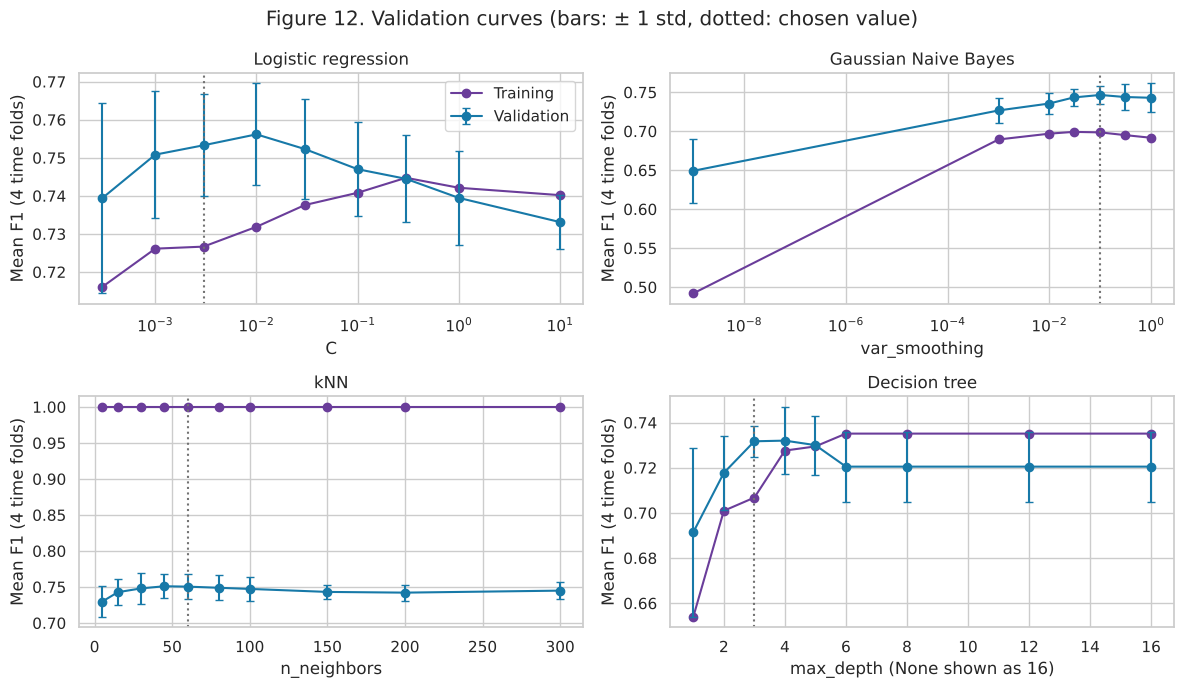

Logistic regression: 18 settings, chosen: C=0.003, class_weight=None, training 0.7267, validation 0.7533 ± 0.0134, AUC 0.8001
value   0.0003   0.0010   0.0030   0.0100   0.0300   0.1000   0.3000   1.0000   10.0000
train    0.7161   0.7261   0.7267   0.7319   0.7376   0.7408   0.7447   0.7421   0.7402
cv       0.7394   0.7508   0.7533   0.7562   0.7523   0.7470   0.7445   0.7395   0.7331
cv std   0.0250   0.0168   0.0134   0.0134   0.0132   0.0123   0.0114   0.0124   0.0072
auc      0.7956   0.7983   0.8001   0.7992   0.7961   0.7919   0.7879   0.7807   0.7579
Gaussian Naive Bayes: 7 settings, chosen: var_smoothing=0.1, training 0.6985, validation 0.7465 ± 0.0112, AUC 0.7838
value   1.000000e-09  1.000000e-03  1.000000e-02  3.000000e-02  1.000000e-01  3.000000e-01  1.000000e+00
train         0.4920        0.6894        0.6969        0.6992        0.6985        0.6951        0.6916
cv            0.6492        0.7266        0.7356        0.7433        0.7465        0.7439        0.7429
cv

In [21]:
# validation curve of the main hyperparameter, the other hyperparameters held at their chosen value
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
curve_values = {}
for ax, name in zip(axes.ravel(), grids):
    parameter = f"model__{regularisation_order[name][0]}"
    settings = searches[name].cv_results_["params"]
    chosen_params = settings[chosen[name]]
    on_curve = [index for index, setting in enumerate(settings)
                if all(setting[key] == chosen_params[key] for key in chosen_params if key != parameter)]
    curve_data = pd.DataFrame(searches[name].cv_results_).loc[on_curve]
    curve_data["value"] = [16 if settings[index][parameter] is None else settings[index][parameter]
                           for index in on_curve]
    curve_data = curve_data.sort_values("value")
    ax.plot(curve_data["value"], curve_data["mean_train_f1"], marker="o", color=PLOT_PURPLE, label="Training")
    ax.errorbar(curve_data["value"], curve_data["mean_test_f1"], yerr=curve_data["std_test_f1"],
                marker="o", capsize=3, color=PLOT_BLUE, label="Validation")
    ax.axvline(chosen_params[parameter] if chosen_params[parameter] is not None else 16, color="0.45",
               linestyle=":", linewidth=1.5)
    if name in ["Logistic regression", "Gaussian Naive Bayes"]:
        ax.set_xscale("log")
    label = parameter.replace("model__", "") + (" (None shown as 16)" if name == "Decision tree" else "")
    ax.set(title=name, xlabel=label, ylabel="Mean F1 (4 time folds)")
    curve_values[name] = curve_data.set_index("value")[["mean_train_f1", "mean_test_f1", "std_test_f1",
                                                         "mean_test_auc"]].round(4)
axes[0, 0].legend()
fig.suptitle("Figure 12. Validation curves (bars: ± 1 std, dotted: chosen value)")
plt.tight_layout()
plt.show()
for name, search in searches.items():
    summary = setting_summary(search, chosen[name])
    print(f"{name}: {len(search.cv_results_['params'])} settings, chosen: {short_setting(search, chosen[name])}, "
          f"training {summary['Train F1']:.4f}, validation {summary['CV F1']:.4f} ± {summary['CV F1 std']:.4f}, "
          f"AUC {summary['CV AUC']:.4f}")
    print(curve_values[name].rename(columns={"mean_train_f1": "train", "mean_test_f1": "cv",
                                             "std_test_f1": "cv std", "mean_test_auc": "auc"}).T.to_string())

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Results and why these values</b></p>
<ul>
  <li><b>Logistic regression</b>: a smaller C means a stronger L2 penalty. From C = 0.01 to 0.3 the training F1 rises (0.732 to 0.745) while the validation F1 falls (0.756 to 0.745): a weak penalty fits patterns of older periods (overfitting). At C = 0.0003 both fall (0.716 and 0.739): underfitting. C = 0.01 has the highest mean (0.7562); C = 0.003 is equal in F1 (0.7533) and higher in AUC (0.8001 against 0.7992) --> <b>C = 0.003</b>. class_weight="balanced" is not chosen: it gives the smaller class more weight, while the F1 is measured on the larger one (repeats)</li>
  <li><b>Gaussian Naive Bayes</b>: var_smoothing adds a share of the largest variance to every variance. Without it (1e-9) the F1 is 0.649; from 0.03 to 1 the curve is flat (0.743 to 0.747) --> <b>0.1</b>, the highest mean; 0.3 is equal in F1 but lower in AUC (0.7817 against 0.7838)</li>
  <li><b>kNN</b>: the training F1 is 1.000 for every k, because with distance weights each training row finds itself, so only the validation F1 counts. 5 neighbours give 0.730; from 45 to 100 the curve is flat (0.747 to 0.751), and beyond 150 it falls slightly (0.742 to 0.745) as customers with a different rhythm enter the vote. k = 45 has the highest mean, k = 60 is equal in F1 and higher in AUC (0.7895 against 0.7867) --> <b>k = 60</b></li>
  <li><b>Decision tree</b>: depth 1 and 2 underfit (0.692 and 0.718); from depth 6 the training F1 keeps rising (0.735) while the validation F1 falls to 0.721, as deeper trees add splits for a few very active customers. Depth 4 has the highest mean (0.7320); depth 3 is equal (0.7317), higher in AUC (0.7633 against 0.7626) and spreads least (± 0.0070) --> <b>depth 3</b>, 25 rows per leaf, ccp_alpha 0.002</li>
</ul>

</div>

<h3>Random forest: parameter by parameter, then a random search</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>The default forest grows every tree until its leaves are pure. Before the joint search, the two parameters that limit the trees are varied one at a time.</p>

</div>

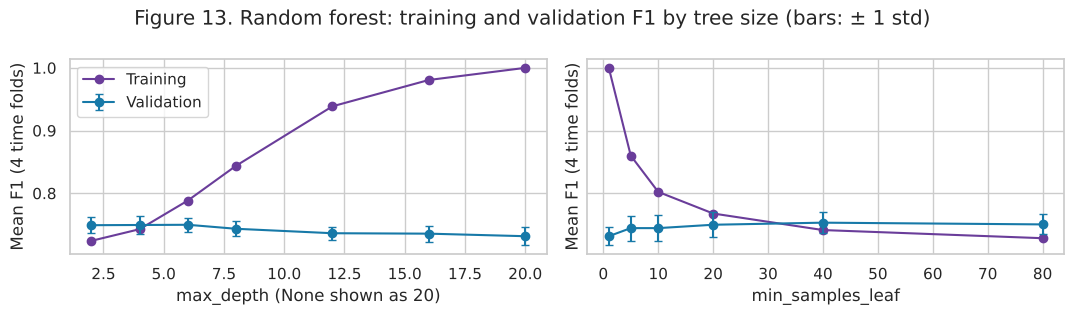

max_depth, training F1: {2: 0.724, 4: 0.743, 6: 0.788, 8: 0.844, 12: 0.939, 16: 0.981, None: 1.0}
max_depth, validation F1: {2: 0.749, 4: 0.749, 6: 0.75, 8: 0.743, 12: 0.736, 16: 0.736, None: 0.732}
min_samples_leaf, training F1: {1: 1.0, 5: 0.86, 10: 0.802, 20: 0.768, 40: 0.741, 80: 0.728}
min_samples_leaf, validation F1: {1: 0.732, 5: 0.744, 10: 0.744, 20: 0.75, 40: 0.753, 80: 0.75}


In [22]:
# random forest: one hyperparameter at a time, the others stay at their default
default_forest = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
forest_grids = {"max_depth": [2, 4, 6, 8, 12, 16, None], "min_samples_leaf": [1, 5, 10, 20, 40, 80]}
forest_curves = {}
for parameter, values in tqdm(forest_grids.items(), desc="random forest curves", leave=True, position=0):
    forest_curves[parameter] = grid_search(
        prep.build_pipeline(default_forest, FINAL_NUMERIC, FINAL_FLAGS, FINAL_CATEGORICAL),
        {f"model__{parameter}": values})
depth_search, leaf_search = forest_curves["max_depth"], forest_curves["min_samples_leaf"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
panels = [(depth_search, "param_model__max_depth", "max_depth (None shown as 20)"),
          (leaf_search, "param_model__min_samples_leaf", "min_samples_leaf")]
for ax, (search, parameter, label) in zip(axes, panels):
    curve_data = pd.DataFrame(search.cv_results_)
    values = pd.to_numeric(curve_data[parameter]).fillna(20)
    ax.plot(values, curve_data["mean_train_f1"], marker="o", color=PLOT_PURPLE, label="Training")
    ax.errorbar(values, curve_data["mean_test_f1"], yerr=curve_data["std_test_f1"],
                marker="o", capsize=3, color=PLOT_BLUE, label="Validation")
    ax.set(xlabel=label, ylabel="Mean F1 (4 time folds)")
axes[0].legend()
fig.suptitle("Figure 13. Random forest: training and validation F1 by tree size (bars: ± 1 std)")
plt.tight_layout()
plt.show()
for search, parameter, _ in panels:
    curve_data = pd.DataFrame(search.cv_results_).set_index(parameter)
    name = parameter.replace("param_model__", "")
    print(f"{name}, training F1:", curve_data["mean_train_f1"].round(3).to_dict())
    print(f"{name}, validation F1:", curve_data["mean_test_f1"].round(3).to_dict())

In [23]:
# random search: 60 settings drawn from lists of values, same folds and random_state
N_SETTINGS = 60


def random_search(name, pipeline, grid):
    started = time.perf_counter()
    search = RandomizedSearchCV(pipeline, grid, n_iter=N_SETTINGS, cv=inner_folds, scoring=SCORING,
                                refit="f1", return_train_score=True, random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X_dev, y_dev)
    search_seconds[name] = time.perf_counter() - started
    print(f"{name}: {N_SETTINGS} settings x 4 folds in {search_seconds[name]:.0f} seconds")
    return search


searches["Random forest"] = random_search(
    "Random forest",
    prep.build_pipeline(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
                        FINAL_NUMERIC, FINAL_FLAGS, FINAL_CATEGORICAL),
    {"model__max_depth": [4, 6, 8, 10, 12, None],
     "model__min_samples_leaf": [5, 10, 20, 40, 80],
     "model__max_features": [0.1, 0.2, 0.3, 0.5, "sqrt"],
     "model__class_weight": [None, "balanced"]})
chosen["Random forest"] = searches["Random forest"].best_index_

Random forest: 60 settings x 4 folds in 139 seconds


<h3>Gradient boosting and neural network</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>Both get the same kind of random search with 60 settings. The lists cover both ends (learning rate 0.01 to 0.3, penalty alpha 0.001 to 30), and both stop training when the score on an internal validation part stops improving.</p>

</div>

In [24]:
searches["Gradient boosting"] = random_search(
    "Gradient boosting",
    prep.build_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE, n_iter_no_change=10,
                                                   validation_fraction=0.2),
                        FINAL_NUMERIC, FINAL_FLAGS, FINAL_CATEGORICAL),
    {"model__learning_rate": [0.01, 0.02, 0.05, 0.1, 0.2, 0.3],
     "model__max_depth": [1, 2, 3, 4],
     "model__n_estimators": [100, 200, 400],
     "model__subsample": [0.6, 0.8, 1.0],
     "model__min_samples_leaf": [10, 30, 60]})
chosen["Gradient boosting"] = searches["Gradient boosting"].best_index_

Gradient boosting: 60 settings x 4 folds in 55 seconds


In [25]:
searches["Neural network (MLP)"] = random_search(
    "Neural network (MLP)",
    prep.build_pipeline(MLPClassifier(max_iter=1000, early_stopping=True, n_iter_no_change=10,
                                      random_state=RANDOM_STATE),
                        FINAL_NUMERIC, FINAL_FLAGS, FINAL_CATEGORICAL),
    {"model__hidden_layer_sizes": [(8,), (16,), (32,), (16, 8), (32, 16)],
     "model__alpha": [0.001, 0.01, 0.1, 1, 3, 10, 30],
     "model__learning_rate_init": [0.0003, 0.001, 0.003, 0.01]})
chosen["Neural network (MLP)"] = searches["Neural network (MLP)"].best_index_

Neural network (MLP): 60 settings x 4 folds in 24 seconds


Gradient boosting, learning_rate: training F1 {0.01: 0.7173, 0.02: 0.7195, 0.05: 0.7237, 0.1: 0.7324, 0.2: 0.7273, 0.3: 0.7323, 0.5: 0.7381}
Gradient boosting, learning_rate: validation F1 {0.01: 0.7447, 0.02: 0.7462, 0.05: 0.744, 0.1: 0.7477, 0.2: 0.7459, 0.3: 0.7409, 0.5: 0.7303}
Neural network (MLP), alpha: training F1 {0.001: 0.7198, 0.01: 0.7198, 0.1: 0.7195, 1: 0.7249, 3: 0.7247, 10: 0.7288, 30: 0.7263}
Neural network (MLP), alpha: validation F1 {0.001: 0.7542, 0.01: 0.7542, 0.1: 0.7544, 1: 0.7436, 3: 0.7523, 10: 0.756, 30: 0.7544}


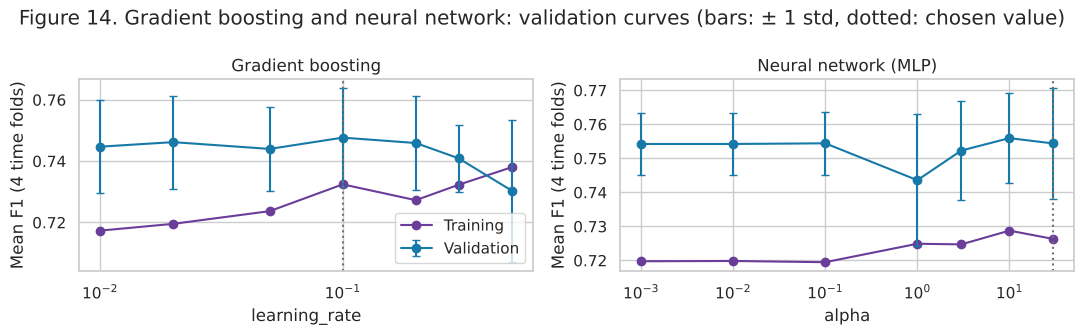

Random forest: validation F1 of the 60 settings from 0.735 to 0.755, best: min_samples_leaf=20, max_features=0.1, max_depth=10, class_weight=None (training 0.754)
Gradient boosting: validation F1 of the 60 settings from 0.699 to 0.748, best: subsample=0.8, n_estimators=400, min_samples_leaf=30, max_depth=1, learning_rate=0.1 (training 0.732)
Neural network (MLP): validation F1 of the 60 settings from 0.667 to 0.754, best: learning_rate_init=0.003, hidden_layer_sizes=(16,), alpha=30 (training 0.726)


In [26]:
# validation curves of the main hyperparameter, the others held at the best setting of the search
curve_specs = [("Gradient boosting", "learning_rate", [0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5]),
               ("Neural network (MLP)", "alpha", [0.001, 0.01, 0.1, 1, 3, 10, 30])]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, (name, parameter, values) in zip(axes, tqdm(curve_specs, desc="validation curves", leave=True, position=0)):
    curve_search = grid_search(clone(searches[name].best_estimator_), {f"model__{parameter}": values})
    curve_data = pd.DataFrame(curve_search.cv_results_)
    ax.plot(values, curve_data["mean_train_f1"], marker="o", color=PLOT_PURPLE, label="Training")
    ax.errorbar(values, curve_data["mean_test_f1"], yerr=curve_data["std_test_f1"],
                marker="o", capsize=3, color=PLOT_BLUE, label="Validation")
    ax.axvline(searches[name].best_params_[f"model__{parameter}"], color="0.45", linestyle=":", linewidth=1.5)
    ax.set_xscale("log")
    ax.set(title=name, xlabel=parameter, ylabel="Mean F1 (4 time folds)")
    print(f"{name}, {parameter}: training F1 {dict(zip(values, curve_data['mean_train_f1'].round(4)))}")
    print(f"{name}, {parameter}: validation F1 {dict(zip(values, curve_data['mean_test_f1'].round(4)))}")
axes[0].legend()
fig.suptitle("Figure 14. Gradient boosting and neural network: validation curves (bars: ± 1 std, dotted: chosen value)")
plt.tight_layout()
plt.show()
for name in ["Random forest", "Gradient boosting", "Neural network (MLP)"]:
    tested = searches[name].cv_results_["mean_test_f1"]
    summary = setting_summary(searches[name], chosen[name])
    print(f"{name}: validation F1 of the 60 settings from {tested.min():.3f} to {tested.max():.3f}, "
          f"best: {short_setting(searches[name], chosen[name])} (training {summary['Train F1']:.3f})")

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Results and why these values</b></p>
<ul>
  <li><b>Random forest</b>: the default forest overfits (training 1.000, validation 0.732, Figure 13). A depth of 6 or less, or 20 or more rows per leaf, lowers the training F1 (0.788 at depth 6, 0.768 with 20 rows) and lifts the validation F1 to about 0.75: averaging limited trees removes the variance of single deep trees. All 60 random settings lie between 0.735 and 0.755 --> once limited, the forest is insensitive to its settings. Best: depth 10, 20 rows per leaf, 10% of the columns per split, with training and validation F1 equal (0.754 and 0.755), so it no longer overfits</li>
  <li><b>Gradient boosting</b>: up to a learning rate of 0.2 the curve is flat (0.744 to 0.748); at 0.5 the training F1 rises (0.738) and the validation F1 falls (0.730), because large steps fit noise (Figure 14). Best: learning rate 0.1 with stumps (depth 1) and up to 400 trees, an additive model close to the logistic regression</li>
  <li><b>Neural network</b>: the penalty alpha hardly matters (0.743 to 0.756, all within the fold spread). Best: 16 hidden units and the strongest penalty (alpha 30), with a training F1 below the validation F1 (0.726) --> the penalty keeps the network close to a linear model</li>
  <li>Every model is best at its regularised end --> the data rewards simple models</li>
</ul>

</div>

<h3>Voting</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>The soft vote averages the probabilities of four tuned models that work in different ways: a linear model, a neighbourhood model, a neural network and bagged trees.</p>

</div>

In [27]:
# soft voting: mean probability of four tuned models
def chosen_model(name):
    return clone(searches[name].best_estimator_).set_params(**searches[name].cv_results_["params"][chosen[name]])["model"]


voting = VotingClassifier(
    estimators=[(key, chosen_model(name)) for key, name in [
        ("logistic", "Logistic regression"), ("knn", "kNN"), ("mlp", "Neural network (MLP)"),
        ("forest", "Random forest")]],
    voting="soft")
voting_row, voting_folds = fold_by_fold(prep.build_pipeline(voting, FINAL_NUMERIC, FINAL_FLAGS, FINAL_CATEGORICAL),
                                       "Voting")
print(f"Voting: training {voting_row['Train F1']:.3f}, validation {voting_row['CV F1']:.4f} "
      f"± {voting_row['CV F1 std']:.4f}, AUC {voting_row['CV AUC']:.4f}, {voting_row['Seconds']:.1f} seconds for 4 folds")

Voting: training 0.967, validation 0.7557 ± 0.0146, AUC 0.8006, 2.7 seconds for 4 folds


<h2>Comparison of performance between candidate models</h2>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>All tuned models side by side: chosen setting, training F1, validation F1 with the fold standard deviation, AUC and the comparison with the model of the highest mean F1.</p>

</div>

In [28]:
# chosen setting and scores of every tuned model, compared with the highest mean F1
comparison_rows = {"Always a repeat (baseline)": {"Chosen setting": "-", "CV F1": baseline_folds.mean(),
                                                  "CV F1 std": baseline_folds.std(), "CV AUC": 0.5}}
fold_scores = {}
for name, search in searches.items():
    comparison_rows[name] = {"Chosen setting": short_setting(search, chosen[name]),
                             **setting_summary(search, chosen[name]),
                             "Fit seconds per fold": search.cv_results_["mean_fit_time"][chosen[name]],
                             "Search seconds": search_seconds.get(name, np.nan)}
    fold_scores[name] = setting_folds(search, chosen[name])
comparison_rows["Voting"] = {"Chosen setting": "soft vote of 4 tuned models",
                             **{key: value for key, value in voting_row.items() if key != "Seconds"},
                             "Fit seconds per fold": voting_row["Seconds"] / len(inner_folds)}
fold_scores["Voting"] = voting_folds

model_comparison = pd.DataFrame(comparison_rows).T.infer_objects()
model_comparison["Train - CV"] = model_comparison["Train F1"] - model_comparison["CV F1"]
model_comparison = model_comparison.sort_values("CV F1", ascending=False)
top_model = model_comparison.index[0]
for name, model_folds in fold_scores.items():
    versus_top = compare_scores(model_folds, fold_scores[top_model])
    model_comparison.loc[name, "Against the highest"] = (
        f"{versus_top['F1 difference']:+.4f}, higher in {versus_top['Folds higher']}/4, {versus_top['Verdict']}")
shown_columns = ["Chosen setting", "Train F1", "CV F1", "CV F1 std", "Train - CV", "CV AUC",
                 "Against the highest", "Fit seconds per fold", "Search seconds"]
model_comparison[shown_columns].round(4).fillna("")

,Chosen setting,Train F1,CV F1,CV F1 std,Train - CV,CV AUC,Against the highest,Fit seconds per fold,Search seconds
Voting,soft vote of 4 tuned models,0.9665,0.7557,0.0146,0.2108,0.8006,"+0.0000, higher in 0/4, equal",0.6639,
Random forest,"min_samples_leaf=20, max_features=0.1, max_depth=10, class_weight=None",0.7542,0.7546,0.0144,-0.0004,0.7980,"-0.0011, higher in 2/4, equal",0.5994,139.2499
Neural network (MLP),"learning_rate_init=0.003, hidden_layer_sizes=(16,), alpha=30",0.7263,0.7544,0.0162,-0.0281,0.7941,"-0.0013, higher in 1/4, equal",0.1027,23.9147
Logistic regression,"C=0.003, class_weight=None",0.7267,0.7533,0.0134,-0.0266,0.8001,"-0.0024, higher in 1/4, equal",0.0326,3.2892
kNN,"n_neighbors=60, weights=distance",1.0,0.7505,0.0172,0.2495,0.7895,"-0.0052, higher in 1/4, equal",0.0246,15.3398
Gradient boosting,"subsample=0.8, n_estimators=400, min_samples_leaf=30, max_depth=1, learning_rate=0.1",0.7324,0.7477,0.0161,-0.0152,0.7861,"-0.0080, higher in 0/4, equal",0.2907,54.7559
Gaussian Naive Bayes,var_smoothing=0.1,0.6985,0.7465,0.0112,-0.048,0.7838,"-0.0091, higher in 0/4, equal",0.024,1.3542
Decision tree,"ccp_alpha=0.002, class_weight=None, max_depth=3, min_samples_leaf=25",0.7068,0.7317,0.0070,-0.0249,0.7633,"-0.0240, higher in 0/4, worse",0.0352,44.8883
Always a repeat (baseline),-,,0.7116,0.0281,,0.5000,,,


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight and decision</b></p>
<ul>
  <li>All tuned models beat the baseline (0.712); only the decision tree is worse than the highest mean (-0.024)</li>
  <li>Voting has the highest mean F1 (0.7557), but random forest, neural network, logistic regression, kNN, gradient boosting and Naive Bayes are equal to it under the rule (-0.001 to -0.009, all within the fold spread)</li>
  <li>Voting and kNN have a training F1 near 1 (0.967 and 1.000) because the distance-weighted kNN recognises each training row; their validation F1 is not higher</li>
  <li><b>Decision: logistic regression with C = 0.003</b>. It is the simplest of the equal models, has the smallest fold spread of the best four (± 0.0134) and the second-highest AUC (0.8001 against 0.8006 for voting), and its coefficients can be explained (Notebook 3). It is also the fastest of the best four: 0.03 seconds per fold fit and 3 seconds for its whole search on our machine, against 0.60 seconds per fold and 139 seconds for the random forest and 0.66 seconds per fold for voting. Its training F1 is below its validation F1 (0.727 against 0.753) because the training rows include early years with fewer repeats, not because of underfitting: a weaker penalty does not raise the validation F1 (Figure 12)</li>
</ul>

</div>

<h3>Threshold of the chosen model</h3>

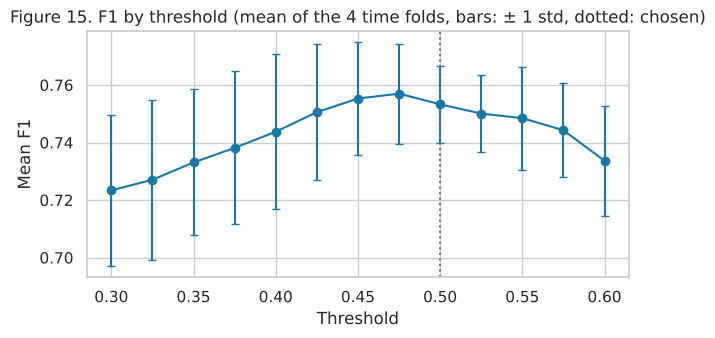

Mean F1 by threshold: {0.3: 0.723, 0.325: 0.727, 0.35: 0.733, 0.375: 0.738, 0.4: 0.744, 0.425: 0.751, 0.45: 0.755, 0.475: 0.757, 0.5: 0.753, 0.525: 0.75, 0.55: 0.748, 0.575: 0.744, 0.6: 0.734}
Mean precision by threshold: {0.3: 0.573, 0.325: 0.583, 0.35: 0.596, 0.375: 0.613, 0.4: 0.631, 0.425: 0.652, 0.45: 0.673, 0.475: 0.693, 0.5: 0.711, 0.525: 0.73, 0.55: 0.756, 0.575: 0.78, 0.6: 0.801}
Best threshold: 0.475, compared with 0.5: +0.0037 (equal), threshold used: 0.5


In [29]:
FINAL_MODEL_NAME = "Logistic regression"
final_search = searches[FINAL_MODEL_NAME]
final_params = final_search.cv_results_["params"][chosen[FINAL_MODEL_NAME]]
final_pipeline = clone(final_search.best_estimator_).set_params(**final_params)


# probabilities of the validation rows of every inner fold, refitted per fold
def out_of_fold_probabilities(pipeline):
    probabilities = []
    for fit_idx, val_idx in tqdm(inner_folds, desc="out-of-fold probabilities", unit="fold", leave=True, position=0):
        fitted = clone(pipeline).fit(X_dev.iloc[fit_idx], y_dev.iloc[fit_idx])
        probabilities.append(fitted.predict_proba(X_dev.iloc[val_idx])[:, 1])
    return probabilities


fold_probabilities = out_of_fold_probabilities(final_pipeline)
thresholds = np.round(np.arange(0.30, 0.61, 0.025), 3)
threshold_curve = pd.DataFrame({
    threshold: [f1_score(y_dev.iloc[val_idx], probability >= threshold)
                for (_, val_idx), probability in zip(inner_folds, fold_probabilities)]
    for threshold in thresholds}).T
precision_at = {threshold: np.mean([((probability >= threshold) & (y_dev.iloc[val_idx] == 1)).sum()
                                    / max((probability >= threshold).sum(), 1)
                                    for (_, val_idx), probability in zip(inner_folds, fold_probabilities)])
                for threshold in thresholds}

best_threshold = float(threshold_curve.mean(axis=1).idxmax())
threshold_check = compare_scores(threshold_curve.loc[best_threshold], threshold_curve.loc[0.5])
THRESHOLD = best_threshold if threshold_check["Verdict"] == "better" else 0.5

mean_curve = threshold_curve.mean(axis=1)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.errorbar(thresholds, mean_curve, yerr=threshold_curve.std(axis=1, ddof=0), marker="o", capsize=3, color=PLOT_BLUE)
ax.axvline(THRESHOLD, color="0.45", linestyle=":", linewidth=1.5)
ax.set(title="Figure 15. F1 by threshold (mean of the 4 time folds, bars: ± 1 std, dotted: chosen)",
       xlabel="Threshold", ylabel="Mean F1")
plt.show()
print("Mean F1 by threshold:", mean_curve.round(3).to_dict())
print("Mean precision by threshold:", {float(key): round(float(value), 3) for key, value in precision_at.items()})
print(f"Best threshold: {best_threshold}, compared with 0.5: {threshold_check['F1 difference']:+.4f} "
      f"({threshold_check['Verdict']}), threshold used: {THRESHOLD}")

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight and decision</b></p>
<ul>
  <li>13 thresholds from 0.30 to 0.60 are tested. The highest mean F1 is at 0.475 (0.757), 0.5 gives 0.753 --> equal (+0.0037, within the fold spread), so <b>0.5 stays</b></li>
  <li>A lower threshold predicts more repeats: recall rises, but precision falls (0.711 at 0.5, 0.573 at 0.30); a higher one does the opposite (0.801 at 0.60). With 55% repeats the F1 peaks where both are balanced, close to 0.5 (Figure 15)</li>
</ul>

</div>

<h3>Final check on the holdout</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>Features, model, hyperparameters and threshold are now fixed, and the holdout is used for the first and only time.</p>

</div>

In [30]:
# first use of the holdout: fit on the development part, predict the holdout
final_pipeline.fit(X_dev, y_dev)
holdout_probability = final_pipeline.predict_proba(X_holdout)[:, 1]
holdout_prediction = (holdout_probability >= THRESHOLD).astype(int)
holdout_f1 = f1_score(y_holdout, holdout_prediction)
holdout_auc = roc_auc_score(y_holdout, holdout_probability)

print(f"Final model on the holdout: F1 {holdout_f1:.4f}, AUC {holdout_auc:.4f}, "
      f"share of predicted repeats {holdout_prediction.mean():.3f}")
print(f"Always predicting a repeat: F1 {baseline_holdout:.4f}\n")
print(classification_report(y_holdout, holdout_prediction, target_names=["no repeat", "repeat"], digits=3))

Final model on the holdout: F1 0.7874, AUC 0.8178, share of predicted repeats 0.600
Always predicting a repeat: F1 0.7530

              precision    recall  f1-score   support

   no repeat      0.675     0.681     0.678       427
      repeat      0.790     0.785     0.787       651

    accuracy                          0.744      1078
   macro avg      0.732     0.733     0.733      1078
weighted avg      0.744     0.744     0.744      1078



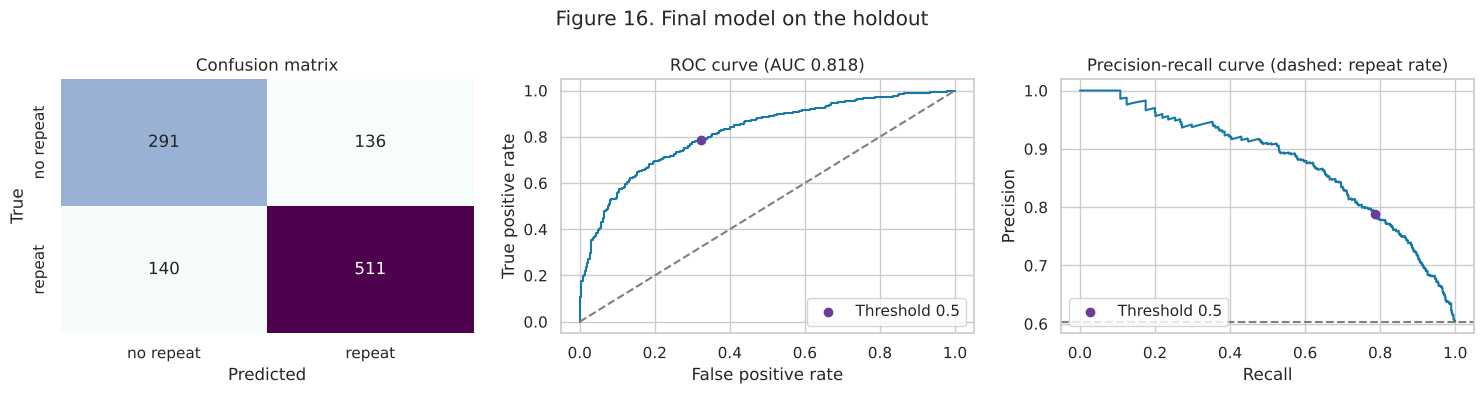

In [31]:
# confusion matrix, ROC curve and precision-recall curve of the holdout
false_positive_rate, true_positive_rate, roc_thresholds = roc_curve(y_holdout, holdout_probability)
precision, recall, pr_thresholds = precision_recall_curve(y_holdout, holdout_probability)
roc_point = np.argmin(np.abs(roc_thresholds - THRESHOLD))
pr_point = np.argmin(np.abs(pr_thresholds - THRESHOLD))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("Figure 16. Final model on the holdout")
sns.heatmap(confusion_matrix(y_holdout, holdout_prediction), annot=True, fmt="d", cmap="BuPu",
            cbar=False, xticklabels=["no repeat", "repeat"], yticklabels=["no repeat", "repeat"],
            ax=axes[0])
axes[0].set(title="Confusion matrix", xlabel="Predicted", ylabel="True")
axes[1].plot(false_positive_rate, true_positive_rate, color=PLOT_BLUE)
axes[1].plot([0, 1], [0, 1], color="grey", linestyle="--")
axes[1].scatter(false_positive_rate[roc_point], true_positive_rate[roc_point], color=PLOT_PURPLE,
                zorder=3, label=f"Threshold {THRESHOLD}")
axes[1].set(title=f"ROC curve (AUC {holdout_auc:.3f})", xlabel="False positive rate",
            ylabel="True positive rate")
axes[1].legend(loc="lower right")
axes[2].plot(recall, precision, color=PLOT_BLUE)
axes[2].axhline(y_holdout.mean(), color="grey", linestyle="--")
axes[2].scatter(recall[pr_point], precision[pr_point], color=PLOT_PURPLE, zorder=3,
                label=f"Threshold {THRESHOLD}")
axes[2].set(title="Precision-recall curve (dashed: repeat rate)", xlabel="Recall", ylabel="Precision")
axes[2].legend(loc="lower left")
plt.tight_layout()
plt.show()

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>The final model reaches an F1 of 0.787 (precision 0.790, recall 0.785) and an AUC of 0.818 on the holdout, against 0.753 for always predicting a repeat</li>
  <li>The F1 is higher than on the time folds (0.753) because this period has more repeats (0.604), which also lifts the baseline. The AUC is higher too (0.818 against 0.800) --> no sign of overfitting to the development part</li>
  <li>The two error types are balanced: 136 predicted repeats that did not happen and 140 missed repeats (Figure 16)</li>
  <li>--> we expect a Kaggle F1 of about 0.78 to 0.79, if test.csv has a similar repeat rate</li>
</ul>

</div>

<h3>Final model</h3>

In [32]:
# refit on all training purchases and save the final model for notebook 3
final_pipeline.fit(train.drop(columns=TARGET), train[TARGET])
final_parameters = {name.replace("model__", ""): value for name, value in final_params.items()}
final_summary = setting_summary(final_search, chosen[FINAL_MODEL_NAME])
final_model = {
    "model": FINAL_MODEL_NAME, "parameters": final_parameters, "threshold": THRESHOLD,
    "numeric": FINAL_NUMERIC, "flags": FINAL_FLAGS, "categorical": FINAL_CATEGORICAL,
    "cv_f1": round(float(final_summary["CV F1"]), 4), "cv_f1_std": round(float(final_summary["CV F1 std"]), 4),
    "cv_auc": round(float(final_summary["CV AUC"]), 4),
    "holdout_f1": round(float(holdout_f1), 4), "holdout_auc": round(float(holdout_auc), 4),
}
Path("../logs").mkdir(exist_ok=True)
Path("../logs/final_model.json").write_text(json.dumps(final_model, indent=2) + "\n", encoding="utf-8")
print(f"Saved logs/final_model.json: {FINAL_MODEL_NAME}, {final_parameters}, threshold {THRESHOLD}, "
      f"{len(final_variables)} variables")

Saved logs/final_model.json: Logistic regression, {'C': 0.003, 'class_weight': None}, threshold 0.5, 20 variables


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>The final pipeline is refitted on all 6,469 training rows and saved in logs/final_model.json.</p>

</div>

<h3>Limitations</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li>Feature selection, hyperparameters and threshold were chosen on the same 4 folds; the selection repeated inside the folds and the holdout give the estimates that have not seen their own rows</li>
  <li>With 4 folds the F1 varies by about ±0.01 between periods, so most differences between tuned models are within the noise</li>
  <li>The F1 depends on the repeat rate of the period, which is unknown for test.csv</li>
</ul>

</div>